In [ ]:
# 1B. Implement Feedforward Neural Network (FNN) with Keras and TensorFlow for
# classification of CIFAR-10 dataset using below steps:
# a. Import the necessary packages
# b. Load the training and testing data (CIFAR10)
# c. Define the network architecture using Keras
# d. Train the model using SGD
# e. Evaluate the network
# f. Plot the training loss and accuracy

# Load → Normalize → Encode → Build → Compile → Train → Evaluate → Plot

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split

In [2]:
# Load (test.csv has no labels, so hold out 20% of train.csv as the test set)
train_data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/FNN and CNN/CIFAR10/cifar-10.csv")

X = train_data.drop("label" , axis = 1).values.reshape(-1 , 32 , 32 , 3)
y = train_data["label"].values

x_train , x_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)

In [3]:
# Normalize : 

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

lb = LabelBinarizer()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape= x_train.shape[1:]),
    keras.layers.Flatten(),
    keras.layers.Dense(128 , activation="relu"),
    keras.layers.Dense(10 , activation="softmax")
])

In [5]:
# Compile : 
model.compile(optimizer= keras.optimizers.SGD(learning_rate=0.01) , loss="categorical_crossentropy" , metrics=["accuracy"])

In [6]:
# Train : 
history = model.fit(
    x_train , y_train , epochs = 11 , batch_size = 32 , validation_split = 0.2
)

Epoch 1/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3040 - loss: 1.9441 - val_accuracy: 0.3394 - val_loss: 1.8309
Epoch 2/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 785us/step - accuracy: 0.3722 - loss: 1.7792 - val_accuracy: 0.3839 - val_loss: 1.7418
Epoch 3/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 789us/step - accuracy: 0.4007 - loss: 1.7028 - val_accuracy: 0.3920 - val_loss: 1.6995
Epoch 4/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 755us/step - accuracy: 0.4197 - loss: 1.6507 - val_accuracy: 0.4193 - val_loss: 1.6539
Epoch 5/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 793us/step - accuracy: 0.4348 - loss: 1.6103 - val_accuracy: 0.4291 - val_loss: 1.6136
Epoch 6/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 759us/step - accuracy: 0.4460 - loss: 1.5778 - val_accuracy: 0.4220 - val_loss: 1.6185
Epoch 7/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 763us/step - accuracy: 0.4559 - loss: 1.5538 - val_accuracy: 0.4354 - val_loss: 1.5767
Epoch 8/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 742us/step - accuracy: 0.4655 - l

In [7]:
# Evaluate : 
loss , accuracy = model.evaluate(x_test , y_test , verbose = 0)
print(loss)
print(accuracy)

1.5419422388076782
0.4553000032901764


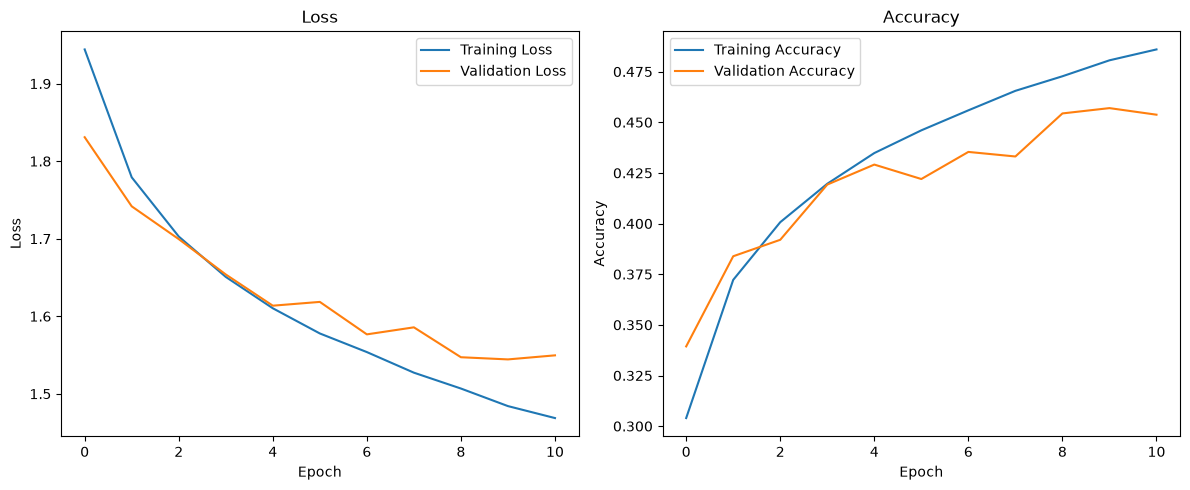

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()